# 89 · Anatomy of a small VLM (SmolVLM-256M): vision encoder → projector → language model, run on TableTop

In [1]:
import time, numpy as np, torch, matplotlib.pyplot as plt
from PIL import Image
from transformers import AutoProcessor, AutoModelForImageTextToText
from vlacourse import TableTop

device = "cuda" if torch.cuda.is_available() else "cpu"
MID = "HuggingFaceTB/SmolVLM-256M-Instruct"
proc = AutoProcessor.from_pretrained(MID)
vlm = AutoModelForImageTextToText.from_pretrained(MID, torch_dtype=torch.bfloat16 if device == "cuda" else torch.float32).to(device).eval()

def ask(img, question, max_new_tokens=60):
    msgs = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": question}]}]
    prompt = proc.apply_chat_template(msgs, add_generation_prompt=True)
    inp = proc(text=prompt, images=[Image.fromarray(img)], return_tensors="pt").to(device)
    with torch.no_grad():
        out = vlm.generate(**inp, max_new_tokens=max_new_tokens, do_sample=False)
    return proc.batch_decode(out[:, inp["input_ids"].shape[1]:], skip_special_tokens=True)[0].strip(), inp

~/anaconda3/envs/vla/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 471/471 [00:00<00:00, 20322.37it/s]

In [2]:
def count(m):
    return sum(p.numel() for p in m.parameters()) / 1e6
parts = {name: count(mod) for name, mod in vlm.model.named_children()}
print("top-level modules (M params):", {k: round(v, 1) for k, v in parts.items()}, "| lm_head", round(count(vlm.lm_head), 1))
print(f"total {count(vlm):.0f}M parameters")

top-level modules (M params): {'vision_model': 86.4, 'connector': 7.1, 'text_model': 134.6} | lm_head 28.4
total 256M parameters


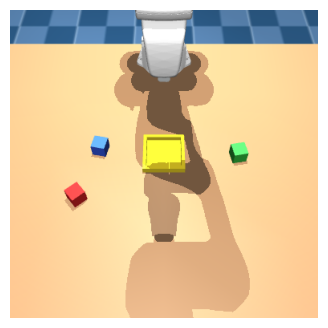

prompt tokens 1142, of which image tokens 1088 | 0.4s
VLM: The table has a wooden floor.


In [3]:
env = TableTop(cameras=("front",), image_size=(384, 384), seed=0)
img = env.reset(seed=11)["images"]["front"]
plt.figure(figsize=(4, 4)); plt.imshow(img); plt.axis("off"); plt.show()
t0 = time.time()
ans, inp = ask(img, "Describe the objects on the table.")
n_img_tokens = int((inp["input_ids"] == vlm.config.image_token_id).sum())
print(f"prompt tokens {inp['input_ids'].shape[1]}, of which image tokens {n_img_tokens} | {time.time() - t0:.1f}s")
print("VLM:", ans)

In [4]:
for q in ["How many cubes are on the table?", "What color is the tray?", "Which cube is closest to the robot gripper?", "Is the red cube inside the yellow tray?"]:
    print(f"Q: {q}\nA: {ask(img, q, 30)[0]}\n")
print("Small VLMs describe scenes well and stumble on precise spatial questions: the gap a VLA's action head must close.")

Q: How many cubes are on the table?
A: There are 4 cubes on the table.

Q: What color is the tray?
A: The tray is blue.



Q: Which cube is closest to the robot gripper?
A: Green.



Q: Is the red cube inside the yellow tray?
A: No, the red cube is not inside the yellow tray.

Small VLMs describe scenes well and stumble on precise spatial questions: the gap a VLA's action head must close.
